# Challenge 3 #

**Objective.** Classify each detected screw or nut by surface finish, using classical colour and texture descriptors. This notebook (1) compares feature sets under **identical image-grouped folds**, (2) measures possible weaknesses caused by highlights, illumination, white balance, and thin masks, and (3) applies the selected classifier to **every available Challenge 1 label image**.

**Data and conventions.** `inputs/<stem>.<extension>` holds the photographs; `annotations/parts.csv` and `annotations/<stem>_labels.png` hold training ground truths; `outputs/challenge_1_results/<stem>_label_image.png` holds predicted part labels. Generated results go to `outputs/challenge_3_results/`. Challenge 1 must be executed first for newly added images. Background pixels have label 0.

The general structure of the notebook goes from:
- Inspecting data overview of the ground truths in \annotations\parts.csv 
- Feature extraction
- Feature analysis
- Model comparision 
- Final classifier
- New-image inferance

## 1. Setup and input discovery

Paths are relative to the notebook's working directory. Ground-truth images are discovered from annotations and it is assumed the stem will match an image in `inputs\` folder.

The feature tables are stored in `outputs/challenge_3_results/` so the trained reference data can still be used if a subsequent `inputs/` folder contains only new, unannotated images.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.feature import graycoprops
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    roc_auc_score, f1_score
)

input_dir = Path("inputs")
annotation_dir = Path("annotations")
prediction_dir = Path("outputs/challenge_1_results")
output_dir = Path("outputs/challenge_3_results")
output_dir.mkdir(parents=True, exist_ok=True)

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# raise error if annotations/parts.csv is missing 
if not (annotation_dir / "parts.csv").exists():
    raise FileNotFoundError("annotations/parts.csv not found")
parts_df = pd.read_csv(annotation_dir / "parts.csv")
required = {"image", "part_id", "finish"}
if not required.issubset(parts_df.columns):
    raise ValueError(f"parts.csv must contain: {sorted(required)}")
if parts_df.duplicated(["image", "part_id"]).any():
    raise ValueError("Duplicate image/part_id rows in annotations/parts.csv")

image_paths = sorted(p for p in input_dir.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions)
image_by_stem = {p.stem: p for p in image_paths}

# ensure no two input images have the same stem but different extension (otherwise parts.cvs will be ambigous)
if len(image_paths) != len(image_by_stem):
    raise ValueError("Multiple input images have the same stem but different extensions")

annotated_paths = [p for p in image_paths
                   if (annotation_dir / f"{p.stem}_labels.png").exists()]
annotated_names = set(parts_df["image"])
complete_annotations = annotated_names.issubset({p.name for p in annotated_paths})

print(f"Input images: {len(image_paths)}")
print(f"Annotated input images available: {len(annotated_paths)}")
print(f"Annotated parts in CSV: {len(parts_df)}")

Input images: 12
Annotated input images available: 10
Annotated parts in CSV: 85


### Data Overview ###

In [2]:
summary_finish = parts_df.groupby(["image", "finish"]).agg({"finish": "count"}).unstack().fillna(0)

# Add the sum of each column to a new row at the bottom
summary_finish.loc["Total"] = summary_finish.sum()

display(summary_finish)

finish                                           \
finish         black-oxidized_steel hot-dip_galvanized_steel stainless_steel   
image                                                                          
screws_026.png                  4.0                      0.0             4.0   
screws_027.png                  4.0                      0.0             4.0   
screws_028.png                  4.0                      0.0             4.0   
screws_029.png                  4.0                      0.0             4.0   
screws_040.png                  0.0                      2.0             8.0   
screws_041.png                  0.0                      2.0             4.0   
screws_042.png                  0.0                      2.0             4.0   
screws_061.png                  2.0                      1.0             2.0   
screws_063.png                  2.0                      1.0             2.0   
screws_119.png                  2.0                      1.0             6.0   
Total                          22.0                      9.0            42.0   

                                         
finish         yellow_zinc-plated_steel  
image                                    
screws_026.png                      0.0  
screws_027.png                      0.0  
screws_028.png                      0.0  
screws_029.png                      0.0  
screws_040.png                      0.0  
screws_041.png                      3.0  
screws_042.png                      3.0  
screws_061.png                      3.0  
screws_063.png                      3.0  
screws_119.png                      0.0  
Total                              12.0

The dataset contains 85 annotated parts across 10 images, classified into four surface finishes: stainless steel, black-oxidized steel, hot-dip galvanized steel and yellow zinc-plated steel. These categories were selected based on the annotated finishes present in the dataset.

Stainless steel is the most common finish (37 parts), while yellow zinc-plated steel is the least common (12 parts). The finishes are unevenly distributed across images, which may affect classification performance.

To evaluate the classification methods, the dataset will be divided into training and testing sets, with 70% used for training and 30% for testing.

In [3]:
from sklearn.model_selection import GroupShuffleSplit

# Split annotated parts by IMAGE (70% training, 30% testing)
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.3,
    random_state=10
)

train_idx, test_idx = next(
    splitter.split(parts_df, groups=parts_df["image"])
)

train_df = parts_df.iloc[train_idx].copy()
test_df = parts_df.iloc[test_idx].copy()

# Check the split
print(f"Training: {train_df['image'].nunique()} images, {len(train_df)} parts")
print(f"Testing:  {test_df['image'].nunique()} images, {len(test_df)} parts")

print("\nTraining finish distribution:")
print(train_df["finish"].value_counts())

print("\nTesting finish distribution:")
print(test_df["finish"].value_counts())

Training: 7 images, 60 parts
Testing:  3 images, 25 parts

Training finish distribution:
finish
stainless_steel             32
black-oxidized_steel        16
hot-dip_galvanized_steel     6
yellow_zinc-plated_steel     6
Name: count, dtype: int64

Testing finish distribution:
finish
stainless_steel             10
black-oxidized_steel         6
yellow_zinc-plated_steel     6
hot-dip_galvanized_steel     3
Name: count, dtype: int64


## Feature Extraction ##

### 1. Colour feature selection ###

Analyse RGB, LAB, and HSV channel distributions over the training images. 

In [4]:
channel_rows = []

for image_name, group in train_df.groupby("image"):

    image = cv2.imread(str(input_dir / image_name))
    labels = cv2.imread(
        str(annotation_dir / f"{Path(image_name).stem}_labels.png"),
        cv2.IMREAD_UNCHANGED
    )

    if image is None or labels is None:
        raise FileNotFoundError(f"Missing image or annotation: {image_name}")

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    channels = {
        "R": rgb[:, :, 0],
        "G": rgb[:, :, 1],
        "B": rgb[:, :, 2],
        "L": lab[:, :, 0],
        "a": lab[:, :, 1],
        "b": lab[:, :, 2],
        "H": hsv[:, :, 0],
        "S": hsv[:, :, 1],
        "V": hsv[:, :, 2],
    }

    for _, part in group.iterrows():

        mask = labels == int(part["part_id"])

        if not mask.any():
            continue

        row = {
            "image": image_name,
            "part_id": part["part_id"],
            "finish": part["finish"]
        }

        for name, channel in channels.items():
            values = channel[mask].astype(float)

            row[f"{name}_median"] = np.median(values)
            row[f"{name}_std"] = np.std(values)

        channel_rows.append(row)

colour_study_df = pd.DataFrame(channel_rows)

display(colour_study_df.head())

,image,part_id,finish,R_median,R_std,G_median,G_std,B_median,B_std,L_median,...,a_median,a_std,b_median,b_std,H_median,H_std,S_median,S_std,V_median,V_std
0,screws_026.png,1,black-oxidized_steel,35.0,13.059104,31.0,13.258032,27.0,9.645122,31.0,...,129.0,4.045294,131.0,4.682595,15.0,35.258890,58.0,32.653972,35.0,15.221268
1,screws_026.png,2,stainless_steel,116.0,54.394632,95.0,51.806381,64.0,55.914377,107.0,...,132.0,9.698459,146.0,14.876145,18.0,34.778194,110.0,42.479943,119.0,55.836820
2,screws_026.png,3,black-oxidized_steel,24.0,20.202629,20.0,17.180566,17.0,11.942065,17.0,...,129.0,3.634902,130.0,5.860792,16.0,45.889136,78.0,41.563725,25.0,20.810686
3,screws_026.png,4,black-oxidized_steel,35.0,21.890952,31.0,17.106153,27.0,11.000106,31.0,...,129.0,4.846426,132.0,6.749289,16.0,33.987648,62.0,38.955447,35.0,23.061776
4,screws_026.png,5,stainless_steel,106.0,49.339218,87.0,47.833403,58.0,51.126359,98.0,...,132.0,7.416922,144.0,13.154898,18.0,30.972184,107.0,42.742078,109.0,51.597221


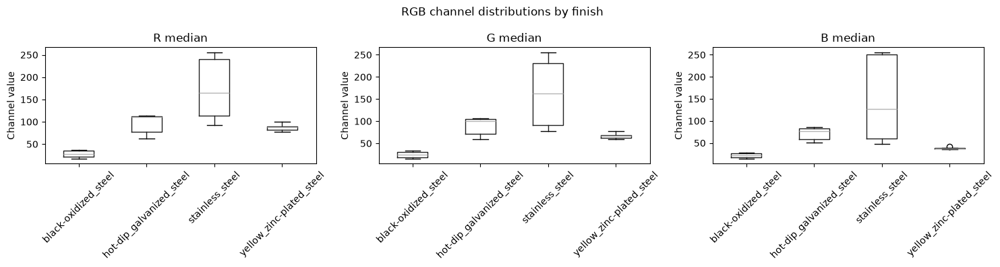

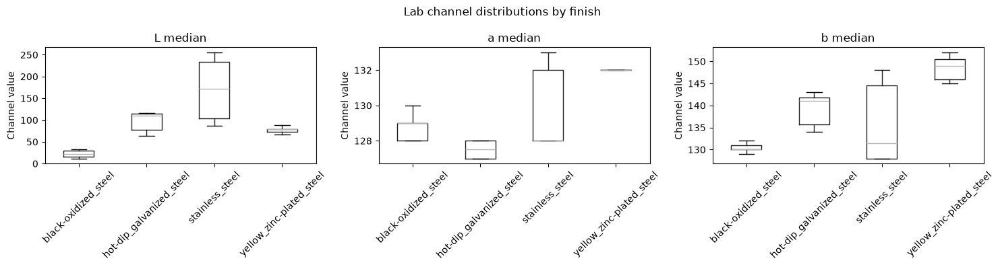

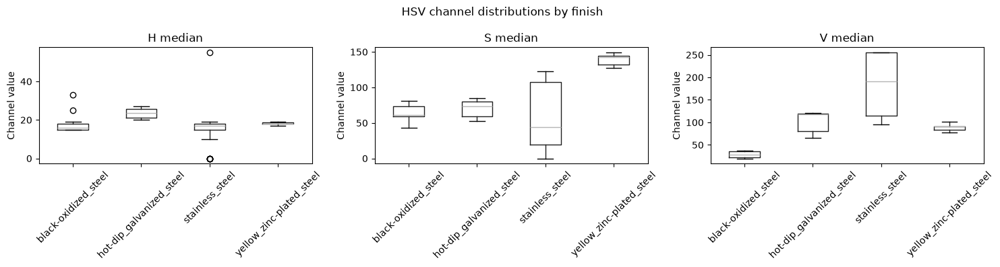

In [5]:
spaces = {
    "RGB": ["R", "G", "B"],
    "Lab": ["L", "a", "b"],
    "HSV": ["H", "S", "V"]
}

for space, channels in spaces.items():

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, channel in zip(axes, channels):

        colour_study_df.boxplot(
            column=f"{channel}_median",
            by="finish",
            ax=ax,
            rot=45,
            grid=False
        )

        ax.set_title(f"{channel} median")
        ax.set_xlabel("")
        ax.set_ylabel("Channel value")

    fig.suptitle(f"{space} channel distributions by finish")
    plt.tight_layout()
    plt.show()

Observations
- **Lab L (lightness):** Black-oxidized steel exhibits consistently low values, supporting lightness as a useful feature for distinguishing darker finishes.
- **Lab b (blue–yellow):** Yellow zinc-plated steel shows higher values than the other finishes, supporting its use for identifying yellow coloration.
- **HSV S (saturation):** Yellow zinc-plated steel exhibits higher saturation with relatively little overlap with other finishes.
- **Limitations:** Considerable overlap exists between stainless steel and hot-dip galvanized steel, suggesting that colour alone may be insufficient to distinguish these finishes reliably.

Based on these observations, six colour descriptors were selected: the medians of Lab L, a, b and HSV saturation, together with the standard deviations of Lab L and HSV saturation.

**Medians** represent the typical colour of each part while reducing sensitivity to isolated extreme pixel values, such as specular highlights. They can also be calculated for small parts, although estimates may become less reliable when very few pixels are available.

**Standard deviations** capture variation in appearance caused by surface characteristics, reflections and shading. However, this variation is not necessarily specific to the surface finish.

**Illumination and white balance:** Lightness descriptors are sensitive to illumination changes, while differences in white balance can shift the colour channels. Therefore, the selected colour statistics do not fully compensate for these effects and remain a limitation of the method.

In [6]:
colour_features = [
    "L_median",
    "a_median",
    "b_median",
    "S_median",
    "L_std",
    "S_std"
]

id_columns = ["image", "part_id", "finish"]

# Keep type if it exists
if "type" in colour_study_df.columns:
    id_columns.append("type")

colour_features_df = colour_study_df[
    id_columns + colour_features
].copy()

display(colour_features_df.head())

,image,part_id,finish,L_median,a_median,b_median,S_median,L_std,S_std
0,screws_026.png,1,black-oxidized_steel,31.0,129.0,131.0,58.0,14.676230,32.653972
1,screws_026.png,2,stainless_steel,107.0,132.0,146.0,110.0,50.853547,42.479943
2,screws_026.png,3,black-oxidized_steel,17.0,129.0,130.0,78.0,19.971035,41.563725
3,screws_026.png,4,black-oxidized_steel,31.0,129.0,132.0,62.0,19.972862,38.955447
4,screws_026.png,5,stainless_steel,98.0,132.0,144.0,107.0,47.308681,42.742078


In [7]:
def extract_colour_features(image, mask):
    """
    Extract six colour descriptors from one part.

    image: BGR image loaded using cv2.imread()
    mask:  2D boolean array identifying the part

    Returns a dictionary containing six numerical features.
    """

    # Convert BGR image to Lab and HSV
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Extract only the pixels belonging to the part
    L = lab[:, :, 0][mask].astype(float)
    a = lab[:, :, 1][mask].astype(float)
    b = lab[:, :, 2][mask].astype(float)
    S = hsv[:, :, 1][mask].astype(float)

    # Calculate colour statistics
    return {
        "L_median": np.median(L),
        "a_median": np.median(a),
        "b_median": np.median(b),
        "S_median": np.median(S),
        "L_std": np.std(L),
        "S_std": np.std(S)
    }


## 2. Texture feature extraction

Grey Level CoMatrix (GLCM) measures how frequently neighbouring grey-level pairs occur. We will investigate how three properties explored in `S4_Exercise_Feature_Extraction_and_Registration` calculates GLCM contrast, homogeneity and energy.

GLCM measures how frequently neighbouring grey-level pairs occur. 
- Contrast: differences between neighbouring intensities (rough or varied appearances)
- Homogeneity: Similarity of neighbouring intensities (smooth or uniform appearances)
- Energy: Concentration of the co-occurrence distribution (consitent or repetitive appearances)

### GLCM parameter selection

GLCM features were extracted from grayscale images to describe local intensity relationships independently of the colour descriptors.

A pixel distance of 1 was selected to capture fine-scale texture of small parts (e.g. smallest nut) while retaining neighbouring pixel pairs for narrow parts. Four directions (0°, 45°, 90° and 135°) were evaluated and averaged to reduce sensitivity to part orientation - particularly for screws which can have any. 

Intensity values were quantised to 32 grey levels, reducing the number of possible intensity pairs and limiting GLCM sparsity for small objects. This reduction introduces a trade-off by losing subtle intensity differences.

Only pixel pairs within the segmented part were included, preventing background texture from influencing the measurements.

These parameters were kept constant across all parts to ensure a consistent comparison. They are practical choices for the borader observations in images rather than experimentally optimised settings.

In [8]:
from skimage.feature import graycoprops

def extract_glcm_features(image, mask):
    """
    Extract GLCM contrast, homogeneity and energy from one part.

    image: BGR image (cv2.imread)
    mask: boolean mask identifying the part

    Uses the class GLCM properties to construct a masked
    GLCM so only metal-to-metal pixel pairs are counted.
    """

    # Convert to grayscale, as in the class GLCM exercise.
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Reduce 256 intensity levels to 32.
    # This limits sparse GLCMs for small, narrow parts.
    levels = 32
    gray = gray // 8

    # Four directions at approximately one-pixel distance.
    # Averaging reduces sensitivity to part orientation.
    offsets = [(0, 1), (1, 1), (1, 0), (1, -1)]

    ys, xs = np.where(mask)
    height, width = gray.shape

    results = {
        "contrast": [],
        "homogeneity": [],
        "energy": []
    }
    total_pairs = 0

    for dy, dx in offsets:

        # Coordinates of neighbouring pixels
        ny = ys + dy
        nx = xs + dx

        # Keep neighbours inside the image
        valid = (
            (ny >= 0) & (ny < height) &
            (nx >= 0) & (nx < width)
        )

        y1, x1 = ys[valid], xs[valid]
        y2, x2 = ny[valid], nx[valid]

        # Keep only pairs where BOTH pixels belong
        # to the metal part, excluding wooden background.
        inside = mask[y2, x2]

        i = gray[y1[inside], x1[inside]]
        j = gray[y2[inside], x2[inside]]

        if len(i) == 0:
            continue

        total_pairs += len(i)

        # Construct the 32 x 32 co-occurrence matrix.
        counts = np.bincount(
            i.astype(int) * levels + j.astype(int),
            minlength=levels**2
        ).reshape(levels, levels)

        # Symmetric GLCM, matching the class exercise.
        counts = counts + counts.T
        counts = counts / counts.sum()

        # graycoprops expects:
        # (levels, levels, distances, angles)
        glcm = counts[:, :, None, None]

        for feature in results:
            value = graycoprops(glcm, feature)[0, 0]
            results[feature].append(value)

    # Tiny regions may contain no valid neighbouring pairs.
    if total_pairs == 0:
        return {
            "contrast": np.nan,
            "homogeneity": np.nan,
            "energy": np.nan,
            "glcm_pairs": 0
        }

    return {
        "contrast": float(np.mean(results["contrast"])),
        "homogeneity": float(np.mean(results["homogeneity"])),
        "energy": float(np.mean(results["energy"])),
        "glcm_pairs": total_pairs
    }


In [9]:

texture_rows = []

for image_name, group in train_df.groupby("image"):

    image_path = input_dir / image_name
    label_path = annotation_dir / (
        f"{Path(image_name).stem}_labels.png"
    )

    image = cv2.imread(str(image_path))
    labels = cv2.imread(
        str(label_path), cv2.IMREAD_UNCHANGED
    )

    if image is None or labels is None:
        raise FileNotFoundError(
            f"Missing image or labels: {image_name}"
        )

    for _, part in group.iterrows():

        part_id = int(part["part_id"])
        mask = labels == part_id

        if not mask.any():
            raise ValueError(
                f"Part {part_id} missing in {image_name}"
            )

        # Extract the same texture features for every part.
        features = extract_glcm_features(image, mask)

        texture_rows.append({
            "image": image_name,
            "part_id": part_id,
            "finish": part["finish"],
            **features
        })

texture_train_df = pd.DataFrame(texture_rows)

print("Training parts:", len(texture_train_df))
print("Parts with no valid pixel pairs:",
      texture_train_df["glcm_pairs"].eq(0).sum())

display(texture_train_df.head())


Training parts: 60
Parts with no valid pixel pairs: 0


,image,part_id,finish,contrast,homogeneity,energy,glcm_pairs
0,screws_026.png,1,black-oxidized_steel,0.906942,0.839652,0.509152,40000
1,screws_026.png,2,stainless_steel,9.473308,0.491050,0.108503,43984
2,screws_026.png,3,black-oxidized_steel,0.944929,0.777826,0.352618,52579
3,screws_026.png,4,black-oxidized_steel,1.502961,0.822081,0.490617,42474
4,screws_026.png,5,stainless_steel,7.879882,0.517571,0.127064,43291


### GLCM distributions by finish

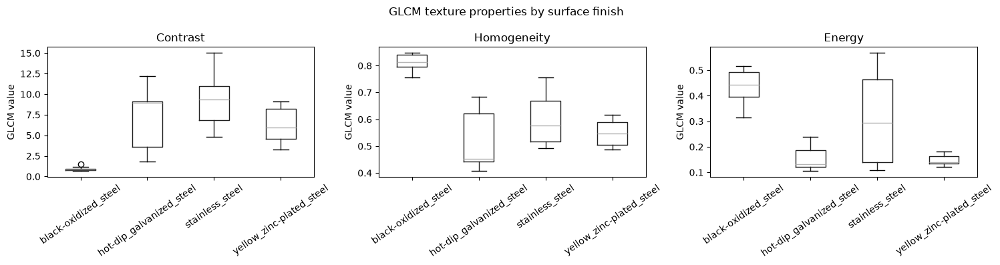

In [10]:

texture_features = ["contrast", "homogeneity", "energy"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, texture_features):

    texture_train_df.boxplot(
        column=feature,
        by="finish",
        ax=ax,
        rot=35,
        grid=False
    )

    ax.set_title(feature.capitalize())
    ax.set_xlabel("")
    ax.set_ylabel("GLCM value")

fig.suptitle("GLCM texture properties by surface finish")
plt.tight_layout()
plt.show()


In [11]:
texture_summary = (
    texture_train_df
    .groupby("finish")[["contrast", "homogeneity", "energy"]]
    .median()
    .round(3)
)

display(texture_summary)

,contrast,homogeneity,energy
finish,,,
black-oxidized_steel,0.866,0.814,0.442
hot-dip_galvanized_steel,8.923,0.452,0.133
stainless_steel,9.385,0.577,0.293
yellow_zinc-plated_steel,5.989,0.547,0.139


The three GLCM properties: contrast, homogeneity and energy, and their distributions were compared using the training data.

Observations:

Black-oxidized steel: Exhibits consistently low contrast, high homogeneity and high energy. Contrast and Homogeneity are particularly discriminative because its distribution is clearly separated from the other finishes, indicating relatively uniform neighbouring pixel intensities.

Hot-dip galvanized steel: Generally has low energy, suggesting a less concentrated distribution of neighbouring intensity pairs. However, overlap exists with other finishes especially stainless steel.

Stainless steel: Has a higher contrast than other finishes but similar to galvanised steel, indicating greater local intensity variation.

Yellow zinc-plated steel: Exhibits intermediate contrast and relatively low energy, but overlaps with several other finishes. No single texture descriptor provides clear separation.

Limitations: Although the GLCM descriptors capture differences in surface appearance, the distributions overlap considerably between several finishes. Additionally, GLCM properties are influenced by object geometry as well as material finish. Nuts have relatively flat surfaces, whereas screws contain threads and edges that may introduce local intensity variations. Differences in thread patterns, even between screws with the same finish, may therefore affect contrast, homogeneity and energy.

Specular reflections and illumination may also influence these measurements. Consequently, the observed texture differences cannot be attributed exclusively to surface finish.

In [12]:
# Add object type from the existing training annotations
texture_with_type = texture_train_df.merge(
    train_df[["image", "part_id", "type"]],
    on=["image", "part_id"],
    how="left"
)

# Compare median texture properties for screws and nuts
display(
    texture_with_type.groupby("type")[
        ["contrast", "homogeneity", "energy"]
    ].median().round(3)
)

,contrast,homogeneity,energy
type,,,
nut,10.324,0.629,0.404
screw,4.952,0.581,0.176


The median GLCM properties were compared between screws and nuts to investigate whether object type influences texture measurements.

Nuts exhibited higher contrast (10.324 versus 4.952) and energy (0.404 versus 0.176), while homogeneity was slightly higher (0.629 versus 0.581).

These differences suggest that the measured texture properties may be influenced by object geometry, reflections and surface characteristics in addition to finish. In particular, the higher contrast observed for nuts demonstrates that threaded geometry does not necessarily produce greater local intensity variation.

This represents a limitation of using GLCM features for finish classification and will be considered when comparing between other feature classification.

<!-- Colour and GLCM texture descriptors are combined to investigate whether complementary information improves surface finish classification.

The colour analysis showed that Lab lightness, Lab b and HSV saturation help distinguish certain finishes, particularly black-oxidized and yellow zinc-plated steel. However, considerable colour overlap was observed between stainless steel and hot-dip galvanized steel.

GLCM descriptors provide additional information about local intensity relationships, potentially helping distinguish finishes with similar colours. However, these measurements may also be influenced by object geometry and reflections.

The combined method therefore uses all six colour and three GLCM descriptors. Its effectiveness will be assessed against the colour-only and texture-only methods using the same classifier and evaluation procedure. -->

In [13]:
# # Merge colour and texture features using image and part ID
# combined_train_df = train_df.merge(
#     texture_train_df[
#         ["image", "part_id", "contrast", "homogeneity", "energy"]
#     ],
#     on=["image", "part_id"],
#     how="inner",
#     validate="one_to_one"
# )

# print(f"Combined training parts: {len(combined_train_df)}")
# display(combined_train_df.head())

## 3. Local Binary Patterns (LBP)

Local Binary Patterns (LBP) were used as a third feature-extraction method to describe local texture. LBP compares each pixel with its surrounding neighbours and encodes the comparisons as a binary pattern. A histogram of these patterns summarises the texture of each part.

The following parameters were selected:

Radius (R=1): Examines neighbouring pixels one pixel away from the centre, capturing fine-scale intensity variations in the small metal parts.

Number of neighbours (P=8): Uses eight surrounding pixels, providing a simple and commonly used description of local texture.

Uniform method (method="uniform"): Groups binary patterns according to their transitions between 0 and 1, reducing the number of texture categories compared with standard LBP.

Histogram bins (bins=10): Uniform LBP with eight neighbours produces ten categories (P + 2), so ten bins are used to represent their frequencies.

The histogram is normalised so that parts of different sizes can be compared.

In [14]:
from skimage.feature import local_binary_pattern

def extract_lbp_features(image, mask):
    
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 8 neighbours, radius of 1 pixel
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")

    # Exclude the wooden background
    values = lbp[mask.astype(bool)]

    # 10 possible LBP categories
    hist, _ = np.histogram(values, bins=10, range=(0, 10))

    # Normalise for different part sizes
    hist = hist / max(hist.sum(), 1)

    return {f"lbp_{i}": float(v) for i, v in enumerate(hist)}

In [15]:
lbp_rows = []

for image_name, parts in train_df.groupby("image"):

    # Load the image
    image = cv2.imread(str(input_dir / image_name))

    # Load the annotated part labels
    labels = cv2.imread(
        str(annotation_dir / f"{Path(image_name).stem}_labels.png"),
        cv2.IMREAD_UNCHANGED
    )

    # Extract features for each annotated part
    for _, part in parts.iterrows():
        mask = labels == part["part_id"]

        features = extract_lbp_features(image, mask)

        lbp_rows.append({
            "image": image_name,
            "part_id": part["part_id"],
            "finish": part["finish"],
            **features
        })

# Create the training feature table
lbp_train_df = pd.DataFrame(lbp_rows)

print(f"LBP features extracted for {len(lbp_train_df)} training parts")
display(lbp_train_df.head())

LBP features extracted for 60 training parts


,image,part_id,finish,lbp_0,lbp_1,lbp_2,lbp_3,lbp_4,lbp_5,lbp_6,lbp_7,lbp_8,lbp_9
0,screws_026.png,1,black-oxidized_steel,0.013020,0.039348,0.024400,0.119201,0.216897,0.209471,0.084193,0.072138,0.143601,0.077732
1,screws_026.png,2,stainless_steel,0.019083,0.025621,0.052655,0.191978,0.284036,0.176164,0.086403,0.053450,0.052566,0.058044
2,screws_026.png,3,black-oxidized_steel,0.019054,0.047005,0.033956,0.104982,0.289072,0.185572,0.081628,0.057236,0.113508,0.067986
3,screws_026.png,4,black-oxidized_steel,0.017051,0.041762,0.027264,0.138324,0.229871,0.192304,0.090271,0.065834,0.120088,0.077232
4,screws_026.png,5,stainless_steel,0.012848,0.037295,0.047645,0.170057,0.312901,0.188348,0.088865,0.059243,0.039436,0.043362


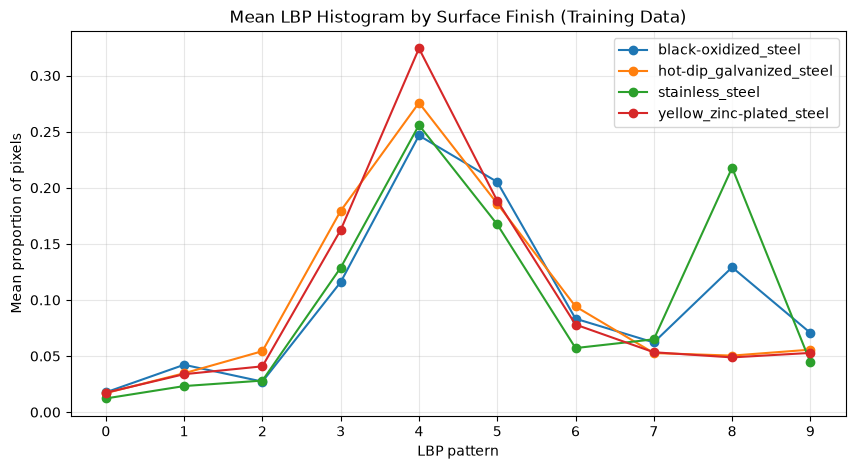

In [16]:
lbp_features = [f"lbp_{i}" for i in range(10)]

# Mean histogram for each finish
mean_lbp = lbp_train_df.groupby("finish")[lbp_features].mean()

# Plot the four finishes
plt.figure(figsize=(10, 5))

for finish in mean_lbp.index:
    plt.plot(
        range(10),
        mean_lbp.loc[finish],
        marker="o",
        label=finish
    )

plt.xlabel("LBP pattern")
plt.ylabel("Mean proportion of pixels")
plt.title("Mean LBP Histogram by Surface Finish (Training Data)")
plt.xticks(range(10))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The mean LBP histograms were compared across the four annotated surface finishes using the training data.

All four finishes exhibit broadly similar histogram shapes, with the highest frequencies occurring at pattern 4. This indicates considerable overlap in their local intensity patterns.

However, some differences are visible. Yellow zinc-plated steel has the highest proportion of pattern 4, while stainless steel exhibits a noticeably higher proportion of pattern 8. Black-oxidized steel also shows a relatively high proportion of pattern 8.

Despite these differences, substantial overlap exists between the mean histograms, particularly between hot-dip galvanized and yellow zinc-plated steel. This suggests that LBP alone may have limited ability to distinguish all four finishes.

Furthermore, LBP measurements may be influenced by object geometry, reflections and background pixels near part boundaries. Since the plot represents average histograms, it does not show variation between individual parts.

## Classifier Selection and Training

The three feature-extraction methods were compared using the same k-Nearest Neighbours (k-NN) classifier. This ensures that differences in classification performance can be attributed primarily to the choice of features rather than differences between classification algorithms.
- Colour statistics — 6 features
- GLCM texture — 3 features
- LBP texture — 10 features

Classifier will have the following parameters:
- SimpleImputer: Handles any missing feature values.
- StandardScaler: Puts features on comparable numerical scales so k-NN distance isn't dominated by larger-valued descriptors.
- k=3: A simple choice suitable for a relatively small training dataset.

The same image-grouped training and test split is used for all methods, ensuring that parts from the same image were not present in both sets.

In [17]:
colour_features = [
    "L_median", "a_median", "b_median",
    "S_median", "L_std", "S_std"
]

glcm_features = ["contrast", "homogeneity", "energy"]

lbp_features = [f"lbp_{i}" for i in range(10)]

feature_sets = {
    "Colour": (colour_study_df, colour_features),
    "GLCM": (texture_train_df, glcm_features),
    "LBP": (lbp_train_df, lbp_features)
}

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

def make_classifier():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

In [19]:
models = {}

for name, (df, features) in feature_sets.items():

    X_train = df[features]
    y_train = df["finish"]

    model = make_classifier()
    model.fit(X_train, y_train)

    models[name] = model

    print(f"{name}: trained using {len(features)} features")

Colour: trained using 6 features
GLCM: trained using 3 features
LBP: trained using 10 features


### Extracting features from test images

In [20]:
test_rows = []

for image_name, parts in test_df.groupby("image"):

    image = cv2.imread(str(input_dir / image_name))

    labels = cv2.imread(
        str(annotation_dir / f"{Path(image_name).stem}_labels.png"),
        cv2.IMREAD_UNCHANGED
    )

    for _, part in parts.iterrows():
        mask = labels == part["part_id"]

        colour = extract_colour_features(image, mask)
        glcm = extract_glcm_features(image, mask)
        lbp = extract_lbp_features(image, mask)

        test_rows.append({
            "image": image_name,
            "part_id": part["part_id"],
            "finish": part["finish"],
            **colour,
            **glcm,
            **lbp
        })

test_features_df = pd.DataFrame(test_rows)

print(f"Test parts: {len(test_features_df)}")
display(test_features_df.head())

Test parts: 25


,image,part_id,finish,L_median,a_median,b_median,S_median,L_std,S_std,contrast,...,lbp_0,lbp_1,lbp_2,lbp_3,lbp_4,lbp_5,lbp_6,lbp_7,lbp_8,lbp_9
0,screws_028.png,1,black-oxidized_steel,17.0,130.0,130.0,79.0,19.692925,42.776429,1.168108,...,0.030484,0.036247,0.032706,0.120061,0.246094,0.217346,0.077286,0.050760,0.117422,0.071592
1,screws_028.png,2,stainless_steel,255.0,128.0,128.0,0.0,51.619489,52.277464,8.200483,...,0.004547,0.005684,0.004926,0.093217,0.187950,0.124290,0.026525,0.088670,0.439560,0.024631
2,screws_028.png,3,stainless_steel,106.0,133.0,148.0,115.0,51.513976,44.183431,11.530759,...,0.025736,0.036704,0.050263,0.182831,0.243026,0.191813,0.072027,0.058382,0.064513,0.074704
3,screws_028.png,4,stainless_steel,100.0,132.0,146.0,112.0,46.029083,42.459970,8.036248,...,0.013907,0.038817,0.044626,0.168647,0.320306,0.184051,0.086700,0.059678,0.038113,0.045154
4,screws_028.png,5,stainless_steel,213.0,128.0,128.0,43.0,68.008636,56.165210,15.517359,...,0.008041,0.013542,0.016081,0.119763,0.248836,0.165468,0.046974,0.092256,0.261955,0.027084


### Comparision of Classification Methods
Classification performance was evaluated using:
- Accuracy: The proportion of test parts assigned the correct surface finish.
- Macro F1-score: The average F1-score across the four finishes, giving each finish equal importance regardless of the number of examples.
- Precision and recall: Used to investigate which finishes are recognised reliably and which are frequently confused with others.
- Confusion matrices: Used to identify the specific types of classification errors.

Higher accuracy and macro F1-scores indicate better overall classification performance. The confusion matrices and per-class results are used to understand the strengths and weaknesses of each method.

All metrics were calculated on the same held-out test data, using ground-truth part masks to evaluate finish classification independently of segmentation errors.

In [21]:
from sklearn.metrics import precision_score, recall_score

results = []

for name, (train_data, features) in feature_sets.items():

    model = models[name]

    X_test = test_features_df[features]
    y_test = test_features_df["finish"]

    predictions = model.predict(X_test)

    # Overall results
    results.append({
        "Method": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

    # Detailed results for each finish
    print(f"\n{name} - Per-finish results")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

# Overall comparison table
results_df = pd.DataFrame(results)

print("\nOverall Method Comparison:")
display(results_df.round(3))


Colour - Per-finish results
                          precision    recall  f1-score   support

    black-oxidized_steel       1.00      1.00      1.00         6
hot-dip_galvanized_steel       1.00      1.00      1.00         3
         stainless_steel       1.00      1.00      1.00        10
yellow_zinc-plated_steel       1.00      1.00      1.00         6

                accuracy                           1.00        25
               macro avg       1.00      1.00      1.00        25
            weighted avg       1.00      1.00      1.00        25


GLCM - Per-finish results
                          precision    recall  f1-score   support

    black-oxidized_steel       1.00      1.00      1.00         6
hot-dip_galvanized_steel       1.00      1.00      1.00         3
         stainless_steel       0.75      0.90      0.82        10
yellow_zinc-plated_steel       0.75      0.50      0.60         6

                accuracy                           0.84        25
               

,Method,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Colour,1.00,1.000,1.000,1.000
1,GLCM,0.84,0.875,0.850,0.855
2,LBP,0.72,0.548,0.725,0.612


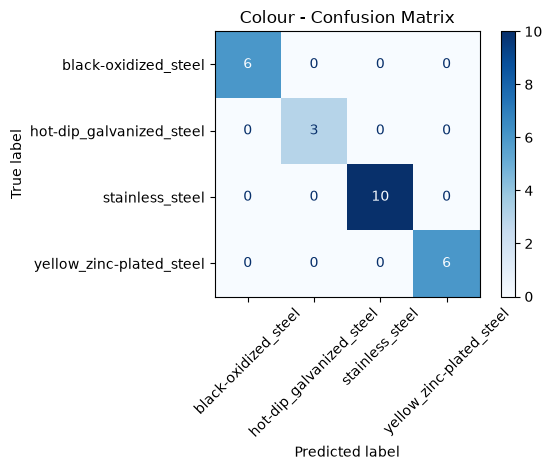

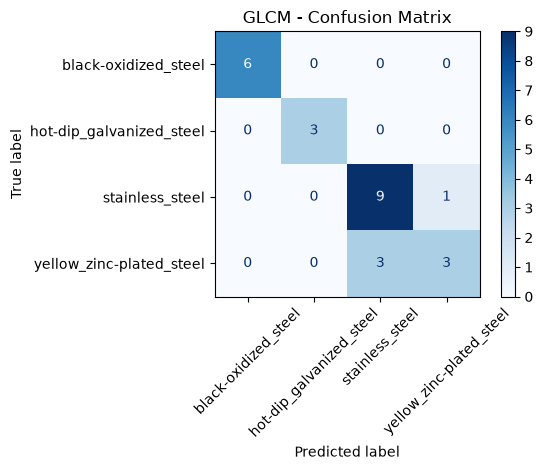

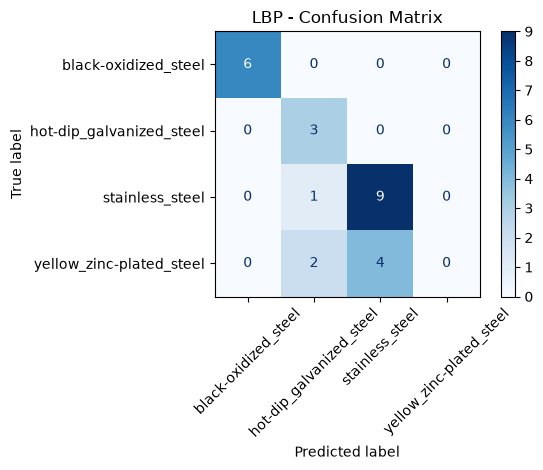

In [22]:
for name, (train_data, features) in feature_sets.items():

    predictions = models[name].predict(test_features_df[features])

    ConfusionMatrixDisplay.from_predictions(
        test_features_df["finish"],
        predictions,
        labels=models[name].classes_,
        xticks_rotation=45,
        cmap="Blues"
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

### Classification Results and Discussion

Colour statistics achieved the best performance, correctly classifying all 25 test parts (100% accuracy and macro F1). This suggests that colour is particularly effective for distinguishing the four surface finishes under the available imaging conditions.

GLCM achieved 84% accuracy and 0.85 macro F1. This shows that texture provides useful discriminatory information, although some confusion occurred between stainless steel and yellow zinc-plated steel.

LBP performed worst, with 72% accuracy and 0.61 macro F1. Notably, it failed to correctly identify any yellow zinc-plated parts, indicating that its local texture patterns were insufficient to distinguish this finish.

Although colour achieved perfect results, the test set contains only 25 parts from three images. Therefore, the result should be interpreted cautiously, as performance may decrease under different illumination conditions or on unseen images.

Overall, colour statistics appear to be the most effective method for this dataset.

## Inspect Challenge 1 outputs with selected features and classification

In [23]:
results = []

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_files = sorted(
    path for path in input_dir.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)

for image_path in image_files:

    image = cv2.imread(str(image_path))

    # Load the predicted labels from Challenge 1
    label_path = prediction_dir / f"{image_path.stem}_label_image.png"

    if not label_path.exists():
        print(f"Missing segmentation: {image_path.name}")
        continue

    labels = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)

    if image is None or labels is None:
        print(f"Could not read: {image_path.name}")
        continue

    # Check that segmentation matches the image size
    if labels.shape != image.shape[:2]:
        print(f"Size mismatch: {image_path.name}")
        continue

    # Each nonzero label represents one detected part
    part_ids = np.unique(labels)
    part_ids = part_ids[part_ids != 0]

    for part_id in part_ids:

        mask = labels == part_id

        # Extract the same features used during training
        features = extract_colour_features(image, mask)

        X_part = pd.DataFrame([features])[colour_features]

        # Predict the surface finish
        predicted_finish = models["Colour"].predict(X_part)[0]

        results.append({
            "image": image_path.name,
            "part_id": int(part_id),
            "predicted_finish": predicted_finish
        })

# Save predictions
finish_predictions_df = pd.DataFrame(
    results,
    columns=["image", "part_id", "predicted_finish"]
)

output_dir.mkdir(parents=True, exist_ok=True)

finish_predictions_df.to_csv(
    output_dir / "finish_predictions.csv",
    index=False
)

print("Images found:", len(image_files))
print("Parts classified:", len(finish_predictions_df))

display(finish_predictions_df.head(10))

Images found: 12
Parts classified: 106


,image,part_id,predicted_finish
0,screws_026.png,1,black-oxidized_steel
1,screws_026.png,2,black-oxidized_steel
2,screws_026.png,3,stainless_steel
3,screws_026.png,4,stainless_steel
4,screws_026.png,5,stainless_steel
5,screws_026.png,6,stainless_steel
6,screws_026.png,7,black-oxidized_steel
7,screws_026.png,8,black-oxidized_steel
8,screws_027.png,1,stainless_steel
9,screws_027.png,2,stainless_steel


In [24]:
def show_challenge3_comparison(image_path, parts_df, finish_predictions_df):

    image = cv2.imread(str(image_path))
    image_name = image_path.name

    gt_path = annotation_dir / f"{image_path.stem}_labels.png"
    pred_path = prediction_dir / f"{image_path.stem}_label_image.png"

    gt_labels = cv2.imread(str(gt_path), cv2.IMREAD_UNCHANGED)
    pred_labels = cv2.imread(str(pred_path), cv2.IMREAD_UNCHANGED)

    if image is None or gt_labels is None or pred_labels is None:
        return

    if gt_labels.shape != pred_labels.shape or gt_labels.shape != image.shape[:2]:
        print(f"Size mismatch: {image_name}")
        return

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(image_rgb)
    axes[0].set_title("Ground-truth finishes")

    axes[1].imshow(image_rgb)
    axes[1].set_title("Predicted finishes (Challenge 1 masks)")

    # Ground-truth labels
    gt_parts = parts_df[parts_df["image"] == image_name]

    for _, part in gt_parts.iterrows():

        mask = gt_labels == part["part_id"]

        if not mask.any():
            continue

        y, x = np.where(mask)
        cx, cy = int(np.median(x)), int(np.median(y))

        axes[0].text(
            cx, cy, part["finish"],
            fontsize=7, color="white",
            ha="center", va="center",
            bbox=dict(facecolor="black", alpha=0.7)
        )

    # Predicted labels
    pred_parts = finish_predictions_df[
        finish_predictions_df["image"] == image_name
    ]

    for _, part in pred_parts.iterrows():

        mask = pred_labels == part["part_id"]

        if not mask.any():
            continue

        y, x = np.where(mask)
        cx, cy = int(np.median(x)), int(np.median(y))

        axes[1].text(
            cx, cy, part["predicted_finish"],
            fontsize=7, color="white",
            ha="center", va="center",
            bbox=dict(facecolor="black", alpha=0.7)
        )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

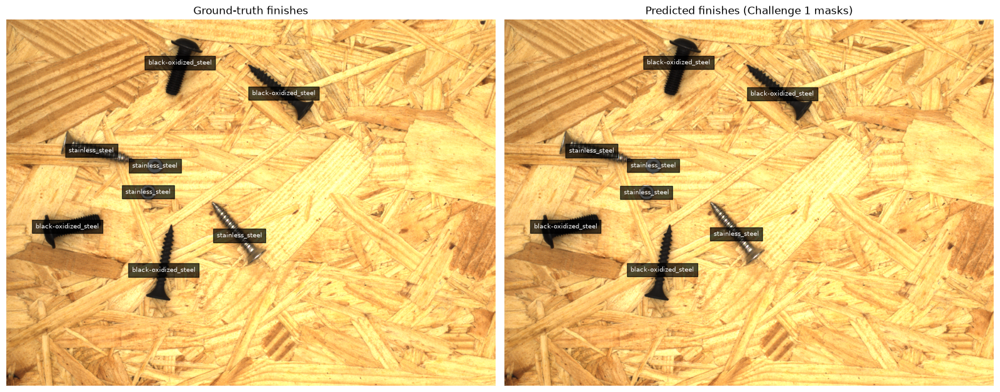

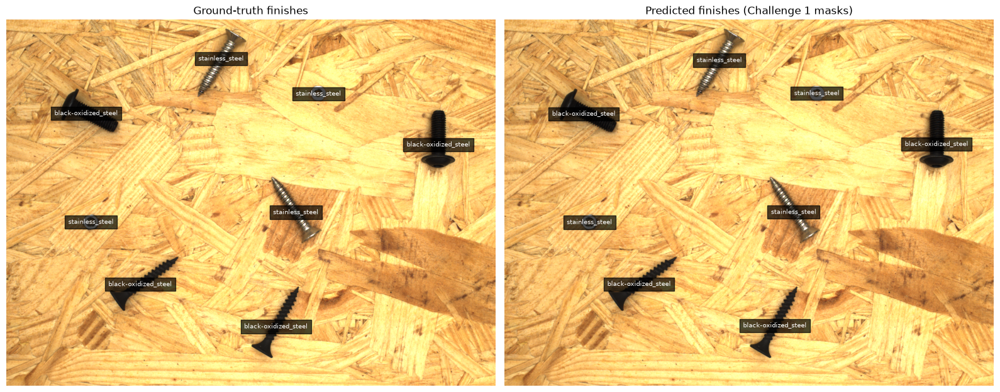

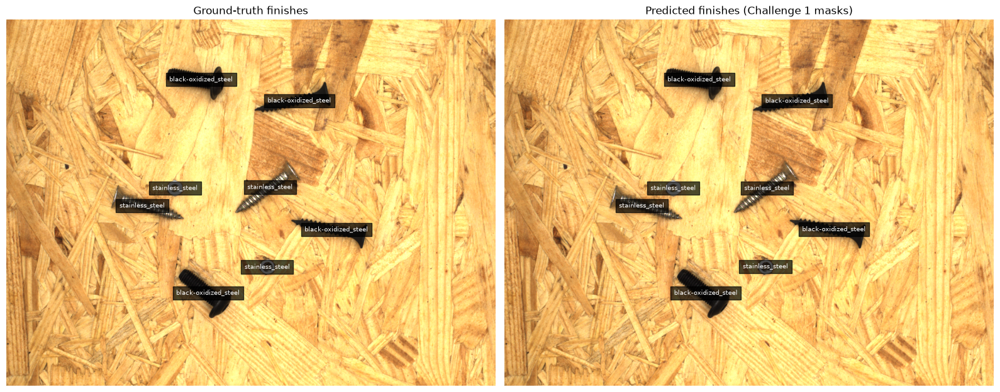

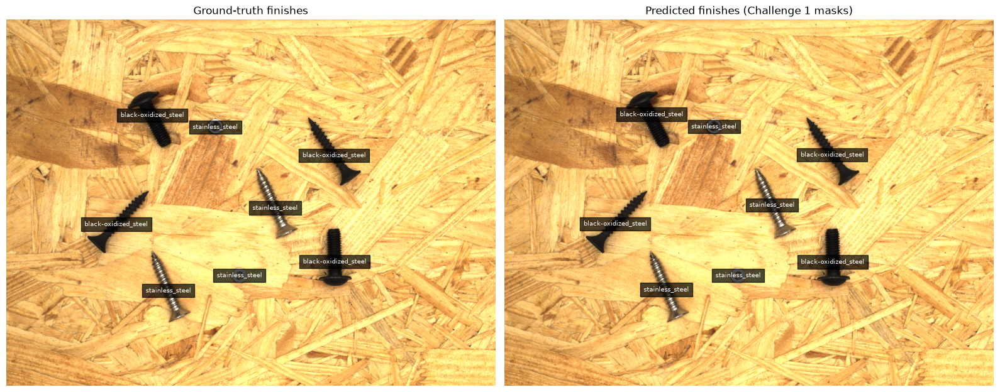

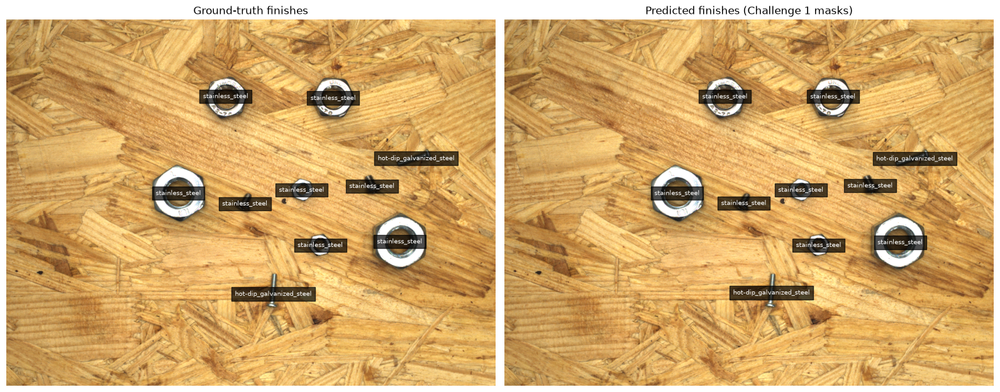

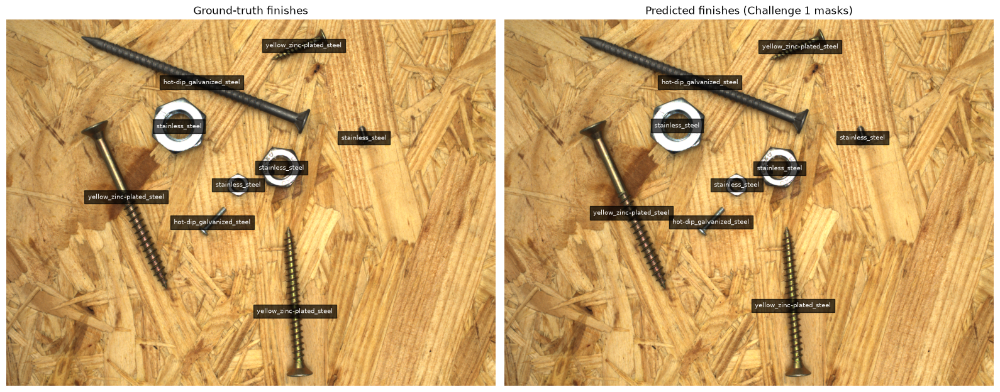

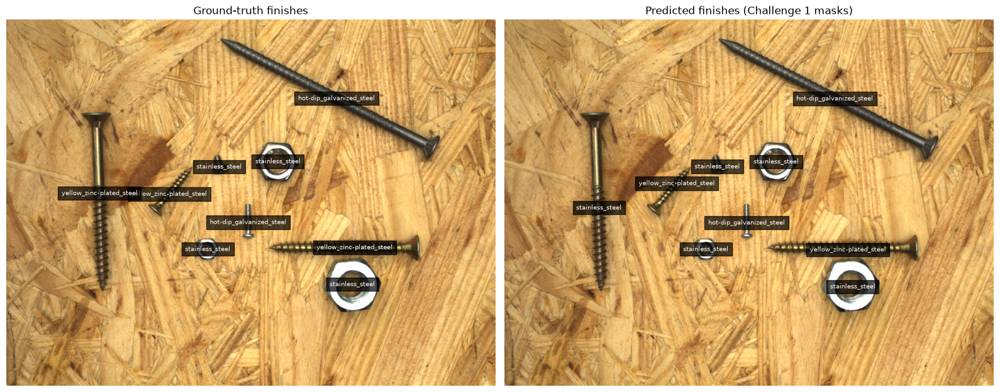

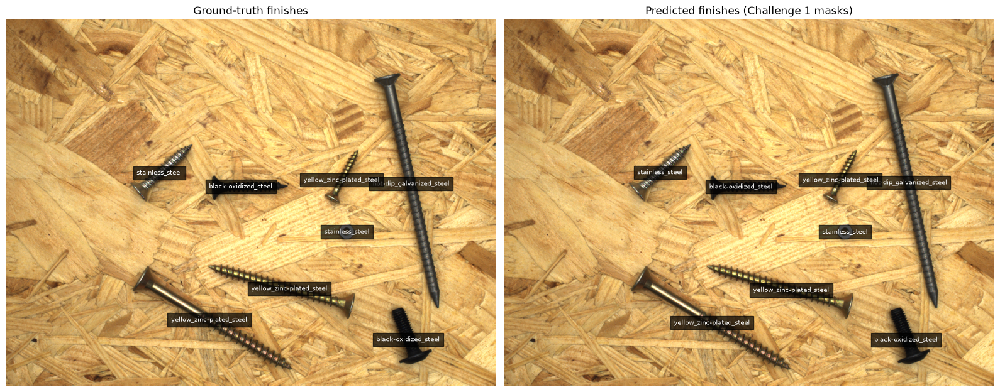

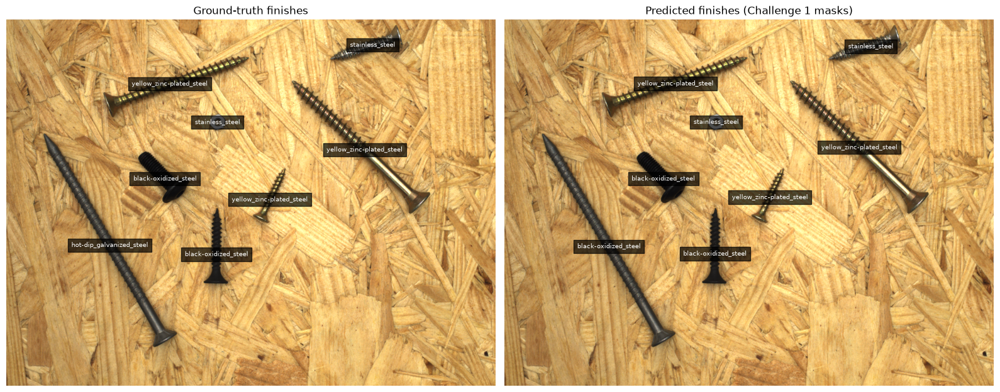

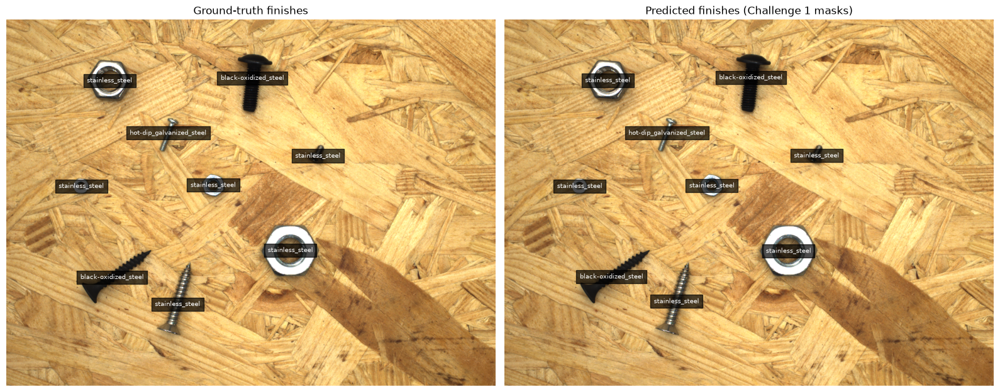

In [25]:
for image_name in sorted(finish_predictions_df["image"].unique()):

    image_path = input_dir / image_name

    gt_path = annotation_dir / f"{image_path.stem}_labels.png"

    if gt_path.exists():
        show_challenge3_comparison(
            image_path,
            parts_df,
            finish_predictions_df
        )